# Preparación del dataset: restauración de fotografías antiguas (Grupo 7)

Descarga automática de **trainA** (fotos antiguas, Library of Congress) y **trainB** (fotos modernas, Wikimedia Commons *Quality images*), con los criterios acordados. Ninguna de las dos fuentes pide clave. **Corran siempre las celdas en orden, de la 1 a la 4**, porque las celdas 3 y 4 definen funciones que usa la 6. El resultado queda en `/content/drive/MyDrive/CycleGAN/`: `trainA.zip`, `trainB.zip` y `fuentes.csv`.

## Celda 1. Montar Drive y configuración

Pongan el correo del grupo en `CONTACTO`, porque Wikimedia lo pide en el User-Agent. Cambien `N_POR_DOMINIO` o las búsquedas si quieren otra mezcla. Cada categoría tiene la misma proporción en A y en B, para que la CycleGAN no confunda el contenido con el estilo.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, io, csv, time, hashlib, random, re
import numpy as np
import requests
from collections import Counter
from PIL import Image, ImageOps
import cv2

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA)

ROOT = "/content/drive/MyDrive/CycleGAN"
FUENTE = f"{ROOT}/dataset_fuente"          # aquí quedan las fotos sueltas (revisables)
DIR = {"A": f"{FUENTE}/trainA", "B": f"{FUENTE}/trainB"}
REGISTRO = f"{FUENTE}/registro.csv"        # todas las candidatas: aceptadas y rechazadas
for d in DIR.values():
    os.makedirs(d, exist_ok=True)

N_POR_DOMINIO = 150                        # 80/20 en el cuaderno → 120 entrenamiento, 30 prueba

# Mismo contenido y mismas proporciones en A y en B
CATEGORIAS = {
    #  nombre     proporción  búsqueda en Library of Congress (A)   búsqueda en Wikimedia Commons (B)
    "retrato": (0.50, ["portrait photograph", "studio portrait"],
                      ["portrait of a man", "portrait of a woman", "portrait person", "portrait elderly", "portrait young"]),
    "urbano":  (0.25, ["street scene", "city street buildings"],
                      ["street pedestrians", "old town street", "main street", "street", "town square", "city street buildings"]),
    "paisaje": (0.25, ["landscape view", "countryside farm view"],
                      ["countryside fields", "farmland", "rural landscape", "landscape", "mountain valley", "lake landscape"]),
}
CUOTA = {c: round(p * N_POR_DOMINIO) for c, (p, _, _) in CATEGORIAS.items()}
CUOTA[list(CUOTA)[0]] += N_POR_DOMINIO - sum(CUOTA.values())   # que sumen exactamente N

LADO_MIN = 256        # lado menor mínimo después del recorte
LADO_GUARDADO = 512   # se reduce el lado menor a 512 px (conserva proporción, zip liviano)
AÑO_MAX_A = 1960
AÑO_MIN_B = 2000      # B: solo fotos tomadas desde el 2000 (fecha EXIF de Commons)
UMBRAL_A = 8.0        # color residual máximo para A (gris/sepia ≈ 0–5)
UMBRAL_B = 15.0       # color residual mínimo para B (fotos a color ≈ 20–60)
MAX_POR_AUTOR = 3     # B: máximo de fotos por fotógrafo en todo el dominio (evita series de un mismo viaje)
PROPORCION_MAX = 2.0  # lado mayor / lado menor; más alargadas se deforman demasiado al llevarlas a 256×256
HAMMING_DUP = 5       # dHash: ≤ 5 bits distintos de 64 = misma foto en otro tamaño

SESION = requests.Session()
# Wikimedia pide un User-Agent que identifique el proyecto y un contacto; pongan el correo del grupo.
CONTACTO = "juan_d.hernandez_l@uao.edu.co"
SESION.headers["User-Agent"] = f"UAO-RNYDL-Grupo7-dataset/1.0 (proyecto academico; {CONTACTO})"
print("Cuotas por categoría:", CUOTA)

Mounted at /content/drive
Cuotas por categoría: {'retrato': 74, 'urbano': 38, 'paisaje': 38}


## Celda 2. Funciones: descarga, filtros, recorte de marcos, duplicados, registro

Criterios automáticos:
- **A:** antes de 1960, gris o sepia (se rechazan las diapositivas a color desteñidas, rosa o moradas, y las imágenes casi en blanco), con los marcos negros y los bordes de papel recortados.
- **B:** a color, tomadas desde el 2000, con un máximo de 3 fotos por fotógrafo.
- **Ambos:**
  - lado menor ≥ 256 px;
  - proporción máxima 2:1 (las panorámicas se deforman al llevarlas a 256×256);
  - en *retrato*, al menos una cara visible de frente (detector Haar de OpenCV);
  - sin duplicados exactos (MD5) ni la misma foto en otro tamaño (dHash).

El umbral del dHash se queda en 5: con 10 confundía retratos distintos con la misma composición. Por eso los casi-duplicados (la misma escena con otro encuadre) se quitan a mano.

Todo queda en `registro.csv` con el motivo de cada rechazo. Si Colab se desconecta, vuelvan a correr la celda y sigue desde donde iba.

In [9]:
class BloqueoLoC(Exception):
    pass

_ULTIMA_LOC_JSON = [0.0]

def descargar(url, headers=None, intentos=4):
    """GET con reintentos.
    - La API JSON de la Library of Congress admite 20 pedidos por minuto y bloquea la IP 1 hora si se
      pasa: aquí se dejan ≥ 4 s entre pedidos a esa API (15 por minuto).
    - Si la LoC responde 403 o 429 se corta en seco: reintentar solo alarga el bloqueo.
    - Para otros servidores, un 429 espera y reintenta."""
    es_json_loc = "loc.gov/photos" in url
    for i in range(intentos):
        if es_json_loc:
            falta = 4.0 - (time.time() - _ULTIMA_LOC_JSON[0])
            if falta > 0: time.sleep(falta)
            _ULTIMA_LOC_JSON[0] = time.time()
        try:
            r = SESION.get(url, headers=headers, timeout=30)
            if "loc.gov" in url and r.status_code in (403, 429):
                raise BloqueoLoC(f"La Library of Congress bloqueó las peticiones (HTTP {r.status_code}). "
                                 "Esperen 1 hora sin pedirle nada y vuelvan a correr.")
            if r.status_code == 429:
                espera = int(r.headers.get("Retry-After", 60))
                print(f"  429 del servidor, espero {espera} s"); time.sleep(espera); continue
            r.raise_for_status()
            return r
        except requests.RequestException as e:
            if i == intentos - 1:
                print("  falló:", url[:90], "|", e); return None
            time.sleep(2 ** i)
    return None

def color_residual(img):
    """Color que NO se explica por un solo tono.
    Se ajusta cada canal de croma (R-G y Y-B) como función lineal del brillo.
    Gris y sepia (un tinte uniforme) quedan casi en 0; una foto a color queda alta.
    Se reduce a 64 px para que el ruido por píxel y la compresión JPEG no pesen."""
    p = img.convert("RGB").copy(); p.thumbnail((64, 64))
    a = np.asarray(p, dtype=np.float64).reshape(-1, 3)
    R, G, B = a.T
    L = 0.299 * R + 0.587 * G + 0.114 * B
    X = np.stack([L, np.ones_like(L)], 1)
    res = 0.0
    for c in (R - G, 0.5 * (R + G) - B):
        coef, *_ = np.linalg.lstsq(X, c, rcond=None)
        res += np.mean((c - X @ coef) ** 2)
    return float(np.sqrt(res))

def estadisticas_color(img):
    """Solo para A. Devuelve (croma95, fracción de tono no cálido, desviación de brillo).
    El gris y el sepia tienen croma bajo y casi todo su tono entre naranja y amarillo (20°–110° en Lab).
    Las diapositivas a color desteñidas (rosa, morado, verde) tienen croma ≥ 20 y > 20 % de píxeles
    fuera de ese rango, aunque `color_residual` las vea como un solo tono.
    La desviación de brillo detecta imágenes casi en blanco."""
    p = img.convert("RGB").copy(); p.thumbnail((128, 128))
    lab = cv2.cvtColor(np.asarray(p), cv2.COLOR_RGB2LAB).astype(np.float64)
    a, b = lab[..., 1] - 128, lab[..., 2] - 128
    ch = np.hypot(a, b)
    con_color = ch > 6
    if con_color.sum() > 50:
        ang = np.degrees(np.arctan2(b[con_color], a[con_color])) % 360
        fuera = float(((ang < 20) | (ang > 110)).mean())
    else:
        fuera = 0.0
    return float(np.percentile(ch, 95)), fuera, float(np.asarray(p.convert("L"), dtype=np.float64).std())

def motivo_color_A(img):
    """None si la foto antigua es gris o sepia con contenido; si no, el motivo de rechazo."""
    c95, fuera, sd = estadisticas_color(img)
    if sd < 15:
        return "casi en blanco"
    if c95 >= 20 and fuera >= 0.2:
        return "tiene color (diapositiva desteñida)"
    if c95 >= 9 and fuera >= 0.3:
        return "tinte frío (azul/verde)"
    if sd < 20 and c95 >= 10:
        return "desteñida (rosa/lavada)"
    return None

def recortar_bordes(img, max_frac=0.15, margen=0.02):
    """Quita marcos negros, bordes de papel y cartón uniforme de las fotos antiguas.
    Desde cada lado elimina filas/columnas muy oscuras o casi uniformes,
    sin pasar de max_frac del tamaño por lado, y luego recorta un margen fijo."""
    g = np.asarray(img.convert("L"), dtype=np.float64)
    h, w = g.shape
    def es_borde(linea):
        return linea.mean() < 40 or linea.std() < 8
    top, bot, izq, der = 0, h, 0, w
    while top < h * max_frac and es_borde(g[top, izq:der]): top += 1
    while h - bot < h * max_frac and es_borde(g[bot - 1, izq:der]): bot -= 1
    while izq < w * max_frac and es_borde(g[top:bot, izq]): izq += 1
    while w - der < w * max_frac and es_borde(g[top:bot, der - 1]): der -= 1
    mh, mw = int((bot - top) * margen), int((der - izq) * margen)
    return img.crop((izq + mw, top + mh, der - mw, bot - mh))

DETECTOR_CARAS = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

def tiene_cara(img):
    """Retrato = se ve al menos una cara de frente que ocupe ≥ 8 % del lado menor.
    Medido sobre las hojas de contacto: descarta casi todas las aves y animales;
    no descarta pinturas ni bustos (eso queda para el filtro de título y la revisión a ojo)."""
    p = img.convert("L").copy(); p.thumbnail((800, 800))
    g = np.asarray(p)
    m = max(24, int(0.08 * min(g.shape)))
    return len(DETECTOR_CARAS.detectMultiScale(g, scaleFactor=1.1, minNeighbors=5, minSize=(m, m))) > 0

def dhash(img):
    """Hash perceptual de 64 bits: igual para la misma foto en distinto tamaño o compresión."""
    p = np.asarray(img.convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
    bits = (p[:, 1:] > p[:, :-1]).ravel()
    return int("".join("1" if b else "0" for b in bits), 2)

def reducir(img):
    w, h = img.size
    f = LADO_GUARDADO / min(w, h)
    return img.resize((round(w * f), round(h * f)), Image.LANCZOS) if f < 1 else img

CAMPOS = ["dominio", "categoria", "archivo", "estado", "motivo", "id_fuente", "titulo",
          "fecha", "autor", "licencia", "url_pagina", "url_imagen", "md5", "dhash", "color_residual"]

def leer_registro():
    if not os.path.exists(REGISTRO):
        return []
    with open(REGISTRO, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

def anotar(fila):
    nuevo = not os.path.exists(REGISTRO)
    with open(REGISTRO, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=CAMPOS)
        if nuevo: w.writeheader()
        w.writerow({k: fila.get(k, "") for k in CAMPOS})

def estado_actual(dominio):
    """Lo que ya existe (para poder reanudar si Colab se desconecta)."""
    reg = leer_registro()
    vistos = {r["id_fuente"] for r in reg if r["dominio"] == dominio}
    aceptadas = [r for r in reg if r["dominio"] == dominio and r["estado"] == "aceptada"
                 and os.path.exists(os.path.join(DIR[dominio], r["archivo"]))]
    md5s = {r["md5"] for r in aceptadas}
    hashes = [int(r["dhash"]) for r in aceptadas]
    cuenta = {c: sum(r["categoria"] == c for r in aceptadas) for c in CATEGORIAS}
    por_autor = Counter(r["autor"] for r in aceptadas)
    return vistos, md5s, hashes, cuenta, por_autor

def procesar(contenido, dominio, md5s, hashes, categoria=None):
    """Aplica los criterios. Devuelve (imagen, md5, dhash, color, motivo_rechazo)."""
    md5 = hashlib.md5(contenido).hexdigest()
    if md5 in md5s:
        return None, md5, None, None, "duplicado exacto"
    try:
        img = ImageOps.exif_transpose(Image.open(io.BytesIO(contenido))).convert("RGB")
    except Exception:
        return None, md5, None, None, "no es imagen"
    if dominio == "A":
        img = recortar_bordes(img)
    if min(img.size) < LADO_MIN:
        return None, md5, None, None, f"muy pequeña {img.size}"
    if max(img.size) / min(img.size) > PROPORCION_MAX:
        return None, md5, None, None, f"muy alargada {img.size}"
    if categoria == "retrato" and not tiene_cara(img):
        return None, md5, None, None, "retrato sin cara visible"
    if dominio == "A":
        m = motivo_color_A(img)
        if m:
            return None, md5, None, None, m
    cr = color_residual(img)
    if dominio == "A" and cr > UMBRAL_A:
        return None, md5, None, cr, "tiene color (¿coloreada?)"
    if dominio == "B" and cr < UMBRAL_B:
        return None, md5, None, cr, "blanco y negro o casi sin color"
    dh = dhash(img)
    if any(bin(dh ^ h).count("1") <= HAMMING_DUP for h in hashes):
        return None, md5, dh, cr, "duplicado (otro tamaño)"
    return reducir(img), md5, dh, cr, None

def guardar(img, dominio, categoria, cuenta, meta, md5, dh, cr, md5s, hashes):
    cuenta[categoria] += 1
    n = 1   # primer número libre (los descartados a mano dejan huecos)
    while os.path.exists(os.path.join(DIR[dominio], f"{categoria}_{dominio}_{n:03d}.jpg")):
        n += 1
    archivo = f"{categoria}_{dominio}_{n:03d}.jpg"
    img.save(os.path.join(DIR[dominio], archivo), "JPEG", quality=92)
    md5s.add(md5); hashes.append(dh)
    anotar({**meta, "dominio": dominio, "categoria": categoria, "archivo": archivo,
            "estado": "aceptada", "md5": md5, "dhash": dh, "color_residual": f"{cr:.1f}"})

## Celda 3. Dominio A: fotos antiguas desde la Library of Congress (sin clave)

Esta celda define `llenar_dominio_A` y la ejecuta. **Siempre hay que correrla después de la celda 2**, aunque las cuotas ya estén completas (en ese caso no descarga nada). La Library of Congress no pide clave. Se omiten las fotos con acceso restringido y los títulos que indican dibujos, grabados, estereoscopías, álbumes, páginas de libro, carteles o mapas.

In [4]:
EXCLUIR_TITULO = re.compile(r"drawing|lithograph|engraving|poster|cartoon|map\b|painting|"
                            r"illustration|sketch|woodcut|etching|postcard|advertis|stereo|album|scrapbook|"
                            r"collage|page\b|book\b|bust\b|statue", re.I)

def tamaño_url_loc(url):
    m = re.search(r"#h=(\d+)&w=(\d+)", url)
    return (int(m.group(2)), int(m.group(1))) if m else (0, 0)

def candidatas_loc(consulta, max_paginas=20):
    """Recorre páginas de resultados y entrega (id, meta, url_imagen) de fotos aptas."""
    for pagina in range(1, max_paginas + 1):
        params = {"q": consulta, "fo": "json", "c": 100, "sp": pagina,
                  "dates": f"1860/{AÑO_MAX_A - 1}",
                  "fa": "original-format:photo, print, drawing|online-format:image"}
        r = descargar("https://www.loc.gov/photos/?" + requests.compat.urlencode(params))
        time.sleep(1.0)   # la LoC limita las búsquedas por minuto
        if r is None: return
        datos = r.json()
        for it in datos.get("results", []):
            urls = it.get("image_url") or []
            titulo = it.get("title", "")
            fechas = it.get("dates") or []
            if not urls or it.get("access_restricted") or EXCLUIR_TITULO.search(titulo):
                continue
            años = [int(x[:4]) for x in fechas if str(x)[:4].isdigit()]
            if not años or max(años) >= AÑO_MAX_A:
                continue
            url = urls[-1]                                     # la versión más grande
            if min(tamaño_url_loc(url)) < LADO_MIN:
                continue
            url = url.split("#")[0].replace("/full/pct:100.0/", "/full/!1024,1024/")
            meta = {"id_fuente": it.get("id", url), "titulo": titulo[:200], "fecha": it.get("date", ""),
                    "autor": "Library of Congress", "licencia": "ver derechos en url_pagina", "url_pagina": it.get("url", ""), "url_imagen": url}
            yield meta["id_fuente"], meta, url
        if not datos.get("pagination", {}).get("next"):
            return

def llenar_dominio_A():
    vistos, md5s, hashes, cuenta, _ = estado_actual("A")
    for cat, (_, consultas_A, _) in CATEGORIAS.items():
        for consulta in consultas_A:
            if cuenta[cat] >= CUOTA[cat]: break
            print(f"[A] {cat}: '{consulta}' ({cuenta[cat]}/{CUOTA[cat]})")
            for idf, meta, url in candidatas_loc(consulta):
                if cuenta[cat] >= CUOTA[cat]: break
                if idf in vistos: continue
                vistos.add(idf)
                r = descargar(url); time.sleep(0.3)
                if r is None: continue
                img, md5, dh, cr, motivo = procesar(r.content, "A", md5s, hashes, cat)
                if motivo:
                    anotar({**meta, "dominio": "A", "categoria": cat, "estado": "rechazada",
                            "motivo": motivo, "md5": md5, "color_residual": cr if cr is None else f"{cr:.1f}"})
                    continue
                guardar(img, "A", cat, cuenta, meta, md5, dh, cr, md5s, hashes)
        print(f"[A] {cat}: {cuenta[cat]}/{CUOTA[cat]}")
    return cuenta

try:
    cuenta_A = llenar_dominio_A()
except BloqueoLoC as e:
    print("⚠", e)

[A] retrato: 'portrait photograph' (71/74)
[A] retrato: 74/74
[A] urbano: 'street scene' (28/38)
[A] urbano: 38/38
[A] paisaje: 'landscape view' (28/38)
[A] paisaje: 38/38


## Celda 4. Dominio B: fotos modernas desde Wikimedia Commons, categoría "Quality images" (sin clave)

Esta celda define `llenar_dominio_B` y la ejecuta. **Siempre hay que correrla después de la celda 2.** Wikimedia Commons no pide clave. Solo se busca dentro de la categoría *Quality images*: fotos revisadas por la comunidad, con buena resolución y sin marcas de agua (Commons no las permite).

Se omiten:
- las fotos de pinturas, esculturas o bustos;
- las tomas nocturnas, los horizontes de ciudad (*skyline*), los interiores y los letreros;
- las fotos sin fecha o tomadas antes del 2000.

El autor y la licencia de cada foto (CC BY-SA, etc.) quedan en `fuentes.csv` para citarlos en el informe.

Máximo 3 fotos por autor, porque un solo fotógrafo puede subir cientos de fotos de un mismo viaje y Commons las devuelve juntas.

In [5]:
EXCLUIR_B = re.compile(r"painting|museum|statue|sculpture|drawing|mural|graffiti|poster|"
                       r"screenshot|map\b|logo|diagram|illustration|mosaic|stained|bust\b|frame|"
                       r"night|skyline|interior|ceiling|dome|sign\b|aerial|church inside", re.I)

def texto_plano(html):
    return re.sub(r"<[^>]+>", "", html or "").strip()

def candidatas_commons(consulta, max_paginas=20):
    """Busca en Quality images (fotos revisadas por la comunidad, sin marcas de agua por política
    de Commons) y entrega solo fotos tomadas desde AÑO_MIN_B."""
    params = {"action": "query", "format": "json", "formatversion": 2,
              "generator": "search", "gsrnamespace": 6, "gsrlimit": 50,
              "gsrsearch": f'{consulta} incategory:"Quality_images" filetype:bitmap',
              "prop": "imageinfo", "iiprop": "url|size|mime|extmetadata", "iiurlwidth": 960,
              "iiextmetadatafilter": "DateTimeOriginal|Artist|LicenseShortName"}
    for _ in range(max_paginas):
        r = descargar("https://commons.wikimedia.org/w/api.php?" + requests.compat.urlencode(params))
        time.sleep(0.5)
        if r is None: return
        datos = r.json()
        for p in (datos.get("query") or {}).get("pages", []):
            info = (p.get("imageinfo") or [{}])[0]
            titulo = p.get("title", "")
            if info.get("mime") not in ("image/jpeg", "image/png") or EXCLUIR_B.search(titulo):
                continue
            ext = info.get("extmetadata") or {}
            fecha = texto_plano(ext.get("DateTimeOriginal", {}).get("value"))
            años = [int(a) for a in re.findall(r"\b(19\d\d|20\d\d)\b", fecha)]
            if not años or min(años) < AÑO_MIN_B:
                continue
            ancho, alto = info.get("thumbwidth", 0), info.get("thumbheight", 0)
            url = info.get("thumburl") or info.get("url")
            if min(ancho, alto) < LADO_MIN or not url:
                continue
            meta = {"id_fuente": f"commons-{p.get('pageid')}", "titulo": titulo[:200], "fecha": fecha[:40],
                    "autor": texto_plano(ext.get("Artist", {}).get("value"))[:120],
                    "licencia": texto_plano(ext.get("LicenseShortName", {}).get("value")),
                    "url_pagina": info.get("descriptionurl", ""), "url_imagen": url}
            yield meta["id_fuente"], meta, url
        if "continue" not in datos:
            return
        params.update(datos["continue"])

def llenar_dominio_B():
    vistos, md5s, hashes, cuenta, por_autor = estado_actual("B")
    for cat, (_, _, consultas_B) in CATEGORIAS.items():
        for consulta in consultas_B:
            if cuenta[cat] >= CUOTA[cat]: break
            print(f"[B] {cat}: '{consulta}' ({cuenta[cat]}/{CUOTA[cat]})")
            for idf, meta, url in candidatas_commons(consulta):
                if cuenta[cat] >= CUOTA[cat]: break
                if idf in vistos or por_autor[meta["autor"]] >= MAX_POR_AUTOR: continue
                vistos.add(idf)
                r = descargar(url); time.sleep(0.5)
                if r is None: continue
                img, md5, dh, cr, motivo = procesar(r.content, "B", md5s, hashes, cat)
                if motivo:
                    anotar({**meta, "dominio": "B", "categoria": cat, "estado": "rechazada",
                            "motivo": motivo, "md5": md5, "color_residual": cr if cr is None else f"{cr:.1f}"})
                    continue
                guardar(img, "B", cat, cuenta, meta, md5, dh, cr, md5s, hashes)
                por_autor[meta["autor"]] += 1
        print(f"[B] {cat}: {cuenta[cat]}/{CUOTA[cat]}")
    return cuenta

cuenta_B = llenar_dominio_B()

[B] retrato: 74/74
[B] urbano: 38/38
[B] paisaje: 38/38


## Celda 5. Hoja de contacto para revisar a ojo (dibujos, marcos que quedaron, marcas de agua)

Revisen a ojo lo que el filtro no detecta: pinturas y bustos (tienen cara), dibujos, álbumes o tarjetas con varias fotos, marcos sin recortar, contenido inapropiado y **escenas que se repiten** (el mismo lugar o la misma persona con otro encuadre).

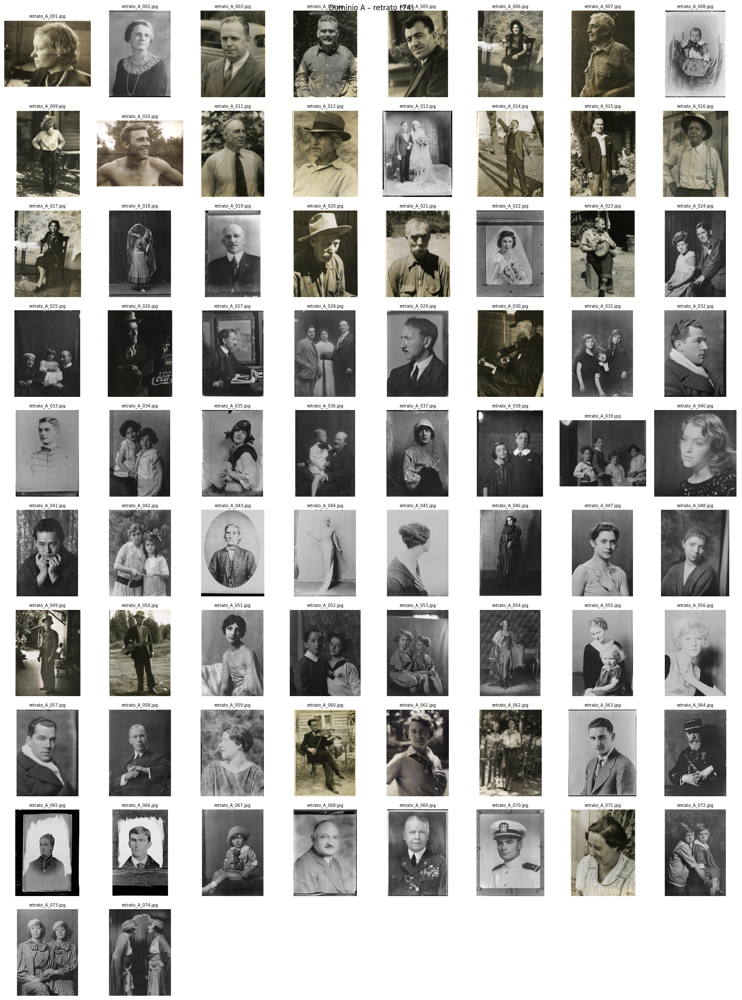

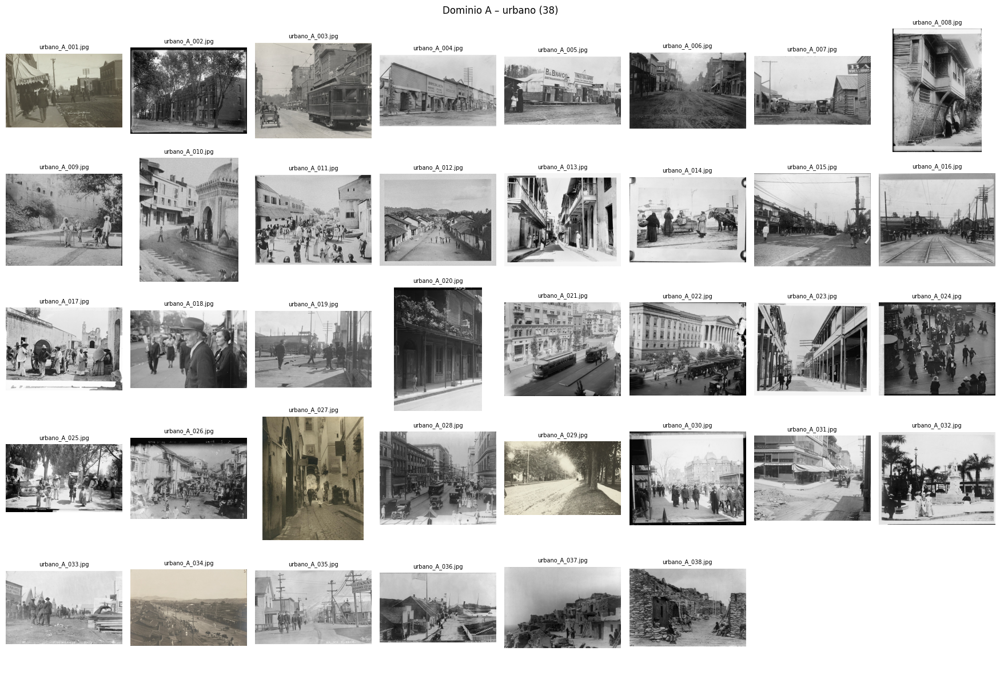

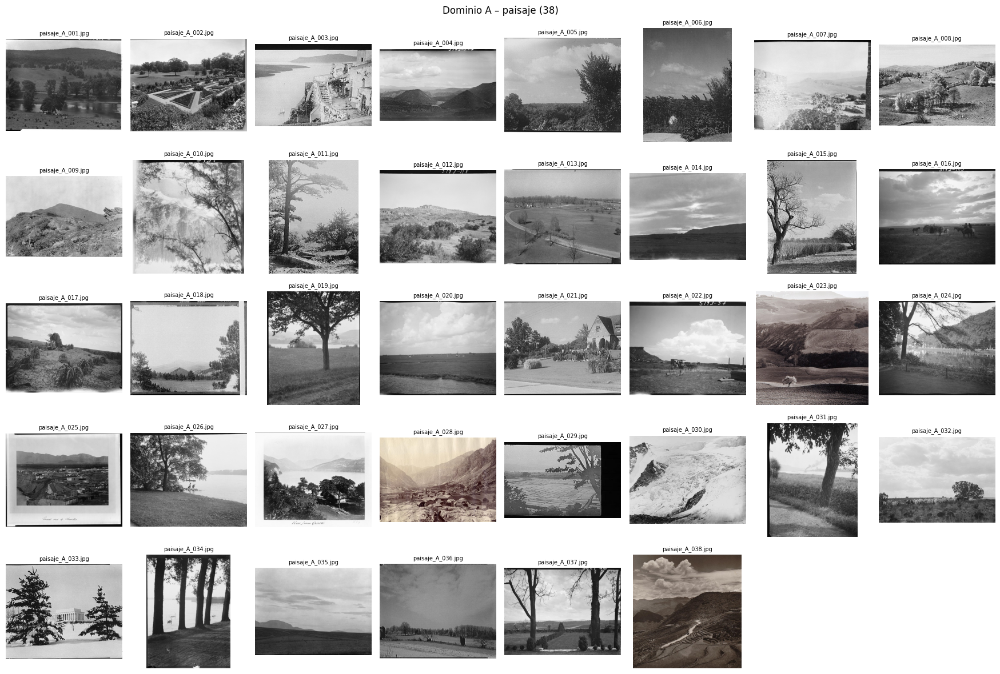

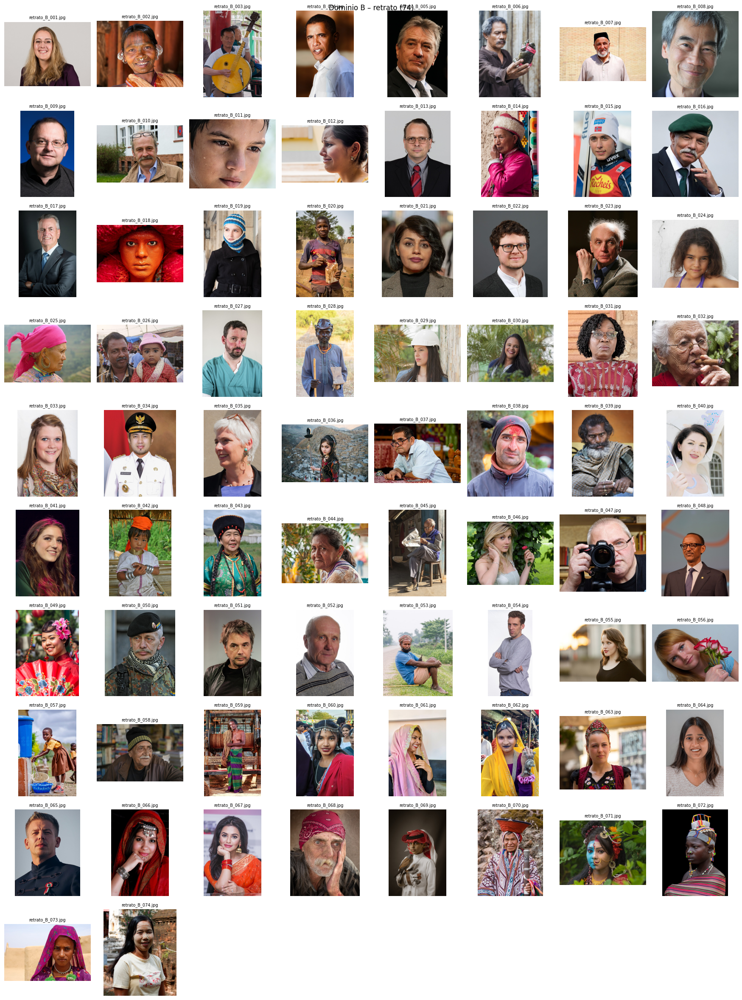

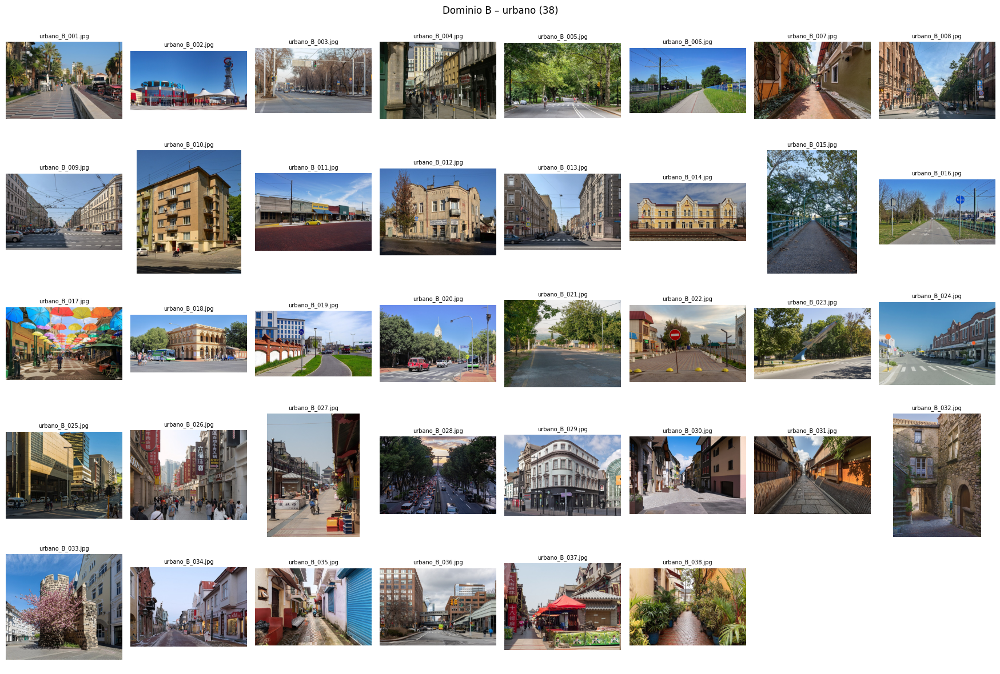

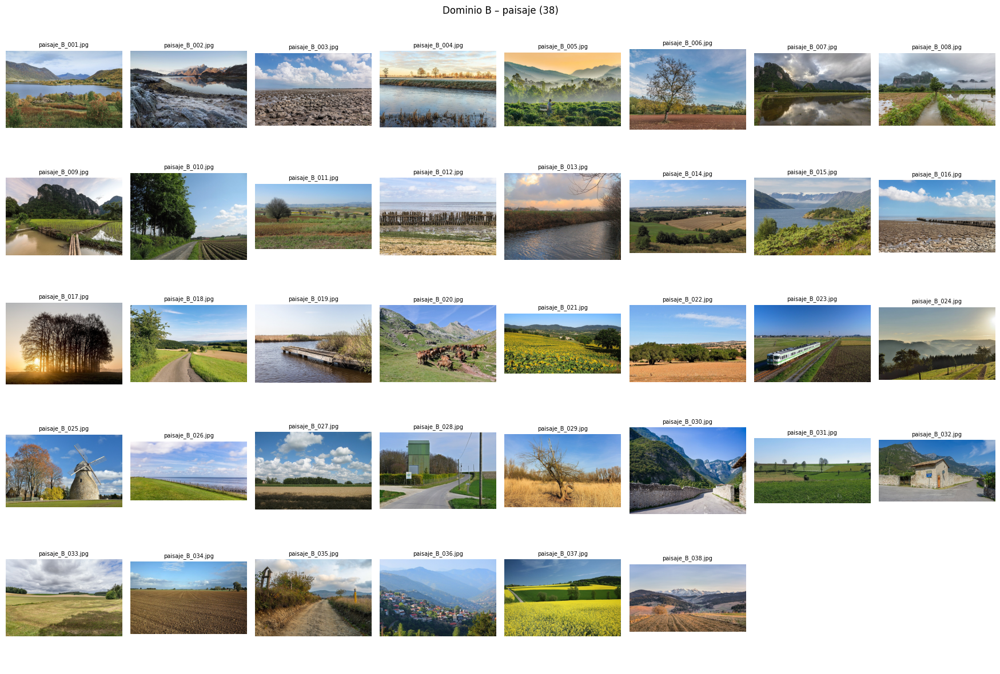

In [15]:
import matplotlib.pyplot as plt

def hoja_de_contacto(dominio, categoria, columnas=8):
    archivos = sorted(f for f in os.listdir(DIR[dominio]) if f.startswith(categoria + "_"))
    if not archivos:
        print("sin fotos"); return
    filas = int(np.ceil(len(archivos) / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(2.2 * columnas, 2.4 * filas))
    for eje in np.atleast_1d(ejes).ravel(): eje.axis("off")
    for eje, f in zip(np.atleast_1d(ejes).ravel(), archivos):
        eje.imshow(Image.open(os.path.join(DIR[dominio], f))); eje.set_title(f, fontsize=7)
    plt.suptitle(f"Dominio {dominio} – {categoria} ({len(archivos)})"); plt.tight_layout(); plt.show()

for dom in ("A", "B"):
    for cat in CATEGORIAS:
        hoja_de_contacto(dom, cat)

## Celda 6. Descartar (automático + a mano) y volver a llenar las cuotas

Primero descarta de forma automática las fotos que no cumplen los criterios nuevos (límite por autor y proporción 2:1). Luego descarta las de la lista `DESCARTAR` y vuelve a llenar las cuotas. Antes de esta celda deben haber corrido la 2, la 3 y la 4.

In [14]:
DESCARTAR = [
]

reg = leer_registro()
# Automático: fotos aceptadas con una versión anterior del cuaderno que no cumplen los criterios nuevos
vistos_autor = Counter()
automaticas = {}
for r in sorted(reg, key=lambda r: (r["dominio"], r["archivo"])):
    if r["estado"] != "aceptada" or not os.path.exists(os.path.join(DIR[r["dominio"]], r["archivo"])):
        continue
    w, h = Image.open(os.path.join(DIR[r["dominio"]], r["archivo"])).size
    if max(w, h) / min(w, h) > PROPORCION_MAX:
        automaticas[r["archivo"]] = "muy alargada"
    elif r["dominio"] == "A":
        m = motivo_color_A(Image.open(os.path.join(DIR["A"], r["archivo"])).convert("RGB"))
        if m:
            automaticas[r["archivo"]] = m
    elif r["dominio"] == "B":
        vistos_autor[r["autor"]] += 1
        if vistos_autor[r["autor"]] > MAX_POR_AUTOR:
            automaticas[r["archivo"]] = "límite por autor"
print("Automáticas:", len(automaticas), dict(Counter(automaticas.values())))

for r in reg:
    if r["estado"] != "aceptada": continue
    motivo = automaticas.get(r["archivo"]) or ("revisión manual" if r["archivo"] in DESCARTAR else None)
    if motivo:
        os.remove(os.path.join(DIR[r["dominio"]], r["archivo"]))
        r["estado"], r["motivo"] = "rechazada", motivo
with open(REGISTRO, "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=CAMPOS); w.writeheader(); w.writerows(reg)
print("Descartadas a mano:", len(DESCARTAR))

# Las descartadas quedan en el registro como vistas, así que no se vuelven a bajar.
RELLENAR_A = True   # pasen a True cuando haya pasado más de 1 hora desde el bloqueo de la LoC
if RELLENAR_A:
    try:
        cuenta_A = llenar_dominio_A()
    except BloqueoLoC as e:
        print("⚠", e)
cuenta_B = llenar_dominio_B()
# Después de esto, vuelvan a correr la celda 5 para revisar solo las nuevas.

Automáticas: 0 {}
Descartadas a mano: 4
[A] retrato: 'portrait photograph' (73/74)
[A] retrato: 74/74
[A] urbano: 'street scene' (36/38)
[A] urbano: 38/38
[A] paisaje: 'landscape view' (37/38)
[A] paisaje: 38/38
[B] retrato: 74/74
[B] urbano: 38/38
[B] paisaje: 38/38


## Celda 7. Crear trainA.zip, trainB.zip y fuentes.csv en /content/drive/MyDrive/CycleGAN

Esto sobrescribe `trainA.zip` y `trainB.zip` en Drive. El cuaderno principal los lee tal cual, con las fotos sueltas en la raíz del zip.

In [16]:
import zipfile
from collections import Counter

reg = [r for r in leer_registro() if r["estado"] == "aceptada"
       and os.path.exists(os.path.join(DIR[r["dominio"]], r["archivo"]))]

for dom in ("A", "B"):
    archivos = sorted(r["archivo"] for r in reg if r["dominio"] == dom)
    destino = f"{ROOT}/train{dom}.zip"
    with zipfile.ZipFile(destino, "w", zipfile.ZIP_STORED) as z:   # JPG ya está comprimido
        for a in archivos:
            z.write(os.path.join(DIR[dom], a), arcname=a)
    print(f"{destino}: {len(archivos)} fotos", dict(Counter(a.split('_')[0] for a in archivos)))

with open(f"{ROOT}/fuentes.csv", "w", newline="", encoding="utf-8") as f:
    campos = ["archivo", "dominio", "categoria", "titulo", "fecha", "autor", "licencia", "url_pagina", "url_imagen"]
    w = csv.DictWriter(f, fieldnames=campos, extrasaction="ignore"); w.writeheader(); w.writerows(reg)

todas = leer_registro()
print("Rechazadas por motivo:", dict(Counter((r["dominio"], r["motivo"]) for r in todas if r["estado"] == "rechazada")))

/content/drive/MyDrive/CycleGAN/trainA.zip: 150 fotos {'paisaje': 38, 'retrato': 74, 'urbano': 38}
/content/drive/MyDrive/CycleGAN/trainB.zip: 150 fotos {'paisaje': 38, 'retrato': 74, 'urbano': 38}
Rechazadas por motivo: {('A', 'tiene color (¿coloreada?)'): 95, ('A', 'muy pequeña (241, 402)'): 1, ('A', 'muy pequeña (245, 402)'): 2, ('A', 'revisión manual'): 118, ('A', 'muy pequeña (241, 370)'): 1, ('A', 'muy pequeña (255, 403)'): 1, ('A', 'muy pequeña (210, 284)'): 1, ('A', 'duplicado (otro tamaño)'): 3, ('A', 'muy alargada'): 5, ('B', 'revisión manual'): 137, ('B', 'blanco y negro o casi sin color'): 56, ('B', 'límite por autor'): 46, ('B', 'muy alargada'): 11, ('A', 'muy alargada (941, 468)'): 1, ('A', 'muy alargada (942, 469)'): 1, ('A', 'muy alargada (984, 316)'): 1, ('B', 'retrato sin cara visible'): 48, ('B', 'muy alargada (960, 266)'): 1, ('B', 'muy alargada (960, 293)'): 1, ('B', 'muy alargada (960, 473)'): 2, ('B', 'muy alargada (960, 289)'): 1, ('A', 'retrato sin cara visible